# Data Preparation

- Creator: Sebastian Birk (sebastian.birk@helmholtz-munich.de).
- Date of Creation: 23.04.2024
- Date of Last Modification: 06.05.2024

## 1. Setup

### 1.1 Import Libraries

In [1]:
import os
import warnings

import anndata as ad
import numpy as np
import pandas as pd
import pyensembl
import scanpy as sc
import squidpy as sq
from skmisc.loess import loess

import nichejepa

INFO:datasets:PyTorch version 2.1.2 available.
INFO:datasets:Polars version 0.20.22 available.
INFO:datasets:JAX version 0.4.26 available.


### 1.2 Run Notebook Setup

In [2]:
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)

Run ```pyensembl install --release 111 --species homo_sapiens```.

In [3]:
ensembl = pyensembl.EnsemblRelease(111)

### 1.3 Configure Paths and Create Directories

In [4]:
# Define paths
st_data_folder_path = "../datasets/st_data" # spatially resolved transcriptomics data
st_data_bronze_folder_path = f"{st_data_folder_path}/bronze"
st_data_silver_folder_path = f"{st_data_folder_path}/silver"
st_data_gold_folder_path = f"{st_data_folder_path}/gold"

# Create required directories
os.makedirs(st_data_bronze_folder_path, exist_ok=True)
os.makedirs(st_data_silver_folder_path, exist_ok=True)
os.makedirs(st_data_gold_folder_path, exist_ok=True)

## 2. Manuscript Data

### 2.1 Nanostring CosMx Human Brain

- Data Access: https://nanostring.com/products/cosmx-spatial-molecular-imager/ffpe-dataset/human-frontal-cortex-ffpe-dataset/

In [5]:
# Read data
df = pd.read_csv(f"{st_data_bronze_folder_path}/S3_exprMat_file.csv.gz")
df_metadata = pd.read_csv(f"{st_data_bronze_folder_path}/S3_metadata_file.csv.gz")

#### 2.1.1 Preprocess Data

In [6]:
## Create adata object
# Only keep genes
genes = [col for col in df.columns if
         ("FalseCode" not in col) &
         ("NegPrb" not in col) &
         ("Custom" not in col) &
         ("cell" not in col) &
         ("fov" not in col)]
df_counts = df[genes]

genes = [gene.split("/")[0] for gene in df_counts.columns]

# Rename some genes with names from Ensembl database
for old_gene_name, new_gene_name in zip(["BAGE", "LILRA3", "COX1", "COX2", "CT45A", "HLA-DRB", "LOC728392", "METTL7A", "SLC9A3R1", "TTC30A"],
                                        ["BAGE2", "ENSG00000275841", "MT-CO1", "MT-CO2", "CT45A1", "HLA-DRB1", "ENSG00000286190", "TMT1A", "NHERF1", "IFT70A"]):
    idx = genes.index(old_gene_name)
    genes[idx] = new_gene_name
    
df_counts.columns = genes

var_metadata = pd.DataFrame(index=df_counts.columns)
obs_metadata = pd.DataFrame(index=df_counts.index, data={"fov": df["fov"].values,
                                                         "cell_id": df["cell_ID"].values,
                                                         "cell": df["cell"].values})

adata = ad.AnnData(X=df_counts.values, obs=obs_metadata, var=var_metadata)

adata.obs["niche_type"] = df_metadata["spatialClusteringAssignments"].values
adata.obs["cell_type"] = df_metadata["RefinedClusts_Final"].values
adata.obs["area"] = df_metadata["Area.um2"].values	

# Convert pixel value to micron
adata.obsm["spatial"] = np.array(
    df_metadata[["CenterX_global_px", "CenterY_global_px"]] * 0.12)

# Get ensembl ids
genes = adata.var.index.tolist()
ensembl_ids = []
for gene in genes:
    try:
        ensembl_ids.append(ensembl.gene_ids_of_gene_name(gene)[0])
    except ValueError as e:
        ensembl_ids.append(gene)
        print(f"Gene {gene} not found in Ensembl release.")
adata.var["ensembl_id"] = ensembl_ids

adata.write(f"{st_data_silver_folder_path}/nanostring_cosmx_human_brain.h5ad")

Gene ENSG00000275841 not found in Ensembl release.
Gene ENSG00000286190 not found in Ensembl release.
Gene MHC I not found in Ensembl release.


... storing 'niche_type' as categorical
... storing 'cell_type' as categorical


In [15]:
# Compute spatial neighborhood graph based on Visium spot diameter of 55 microns
sq.gr.spatial_neighbors(adata,
                        coord_type="generic",
                        spatial_key="spatial",
                        radius=55,
                        )

# Add self loops to spatial neighborhood graph
adata.obsp["spatial_connectivities"].setdiag(1)
    
# Compute sum of counts across each cell's neighborhood to get neighborhood counts per cell
adata.layers["X_neighborhood"] = np.array(adata.obsp["spatial_connectivities"].T @ adata.X)

#### 2.1.2 Visualize Data

In [7]:
adata = sc.read_h5ad(f"{st_data_silver_folder_path}/nanostring_cosmx_human_brain.h5ad")

##### 2.1.2.1 Overview

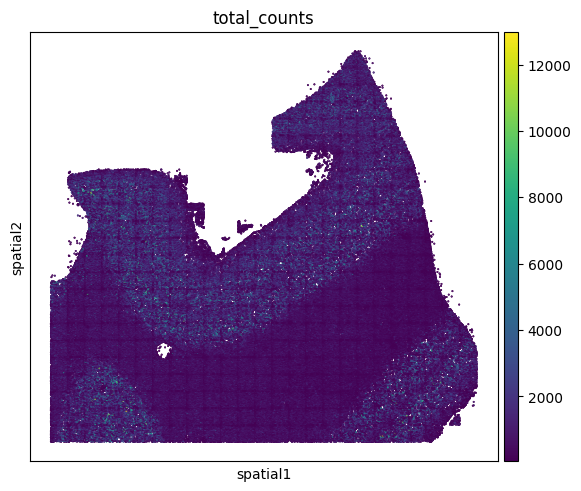

In [8]:
# Check distribution of total counts across space
adata.obs["total_counts"] = adata.X.sum(1)
sq.pl.spatial_scatter(adata, color="total_counts", shape=None) 

In [ ]:
# Visualize example gene in tissue
# sq.pl.spatial_scatter(adata, color="MBP", shape=None)

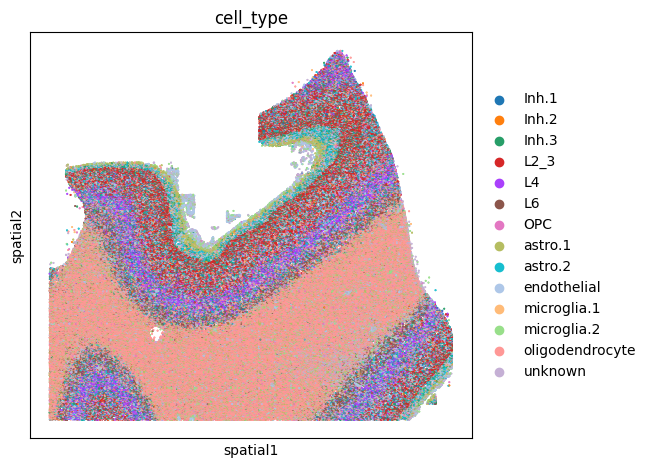

In [9]:
# Visualize cell types in tissue
sq.pl.spatial_scatter(adata, color="cell_type", shape=None) 

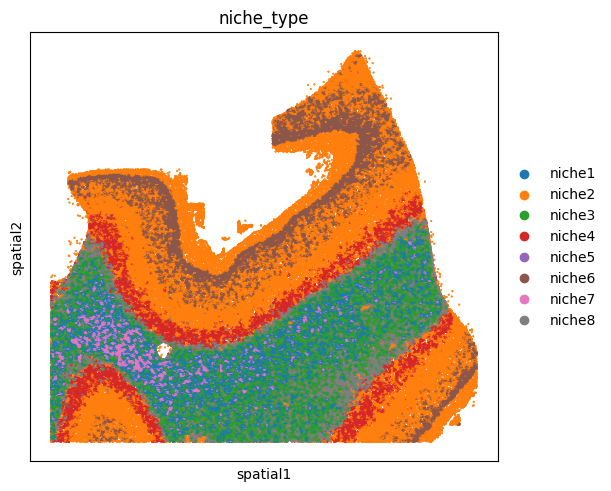

In [10]:
# Visualize niche types in tissue
sq.pl.spatial_scatter(adata, color="niche_type", shape=None) 

##### 2.1.2.2 Raw Counts

In [11]:
# Compute UMAP based on (raw) counts
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

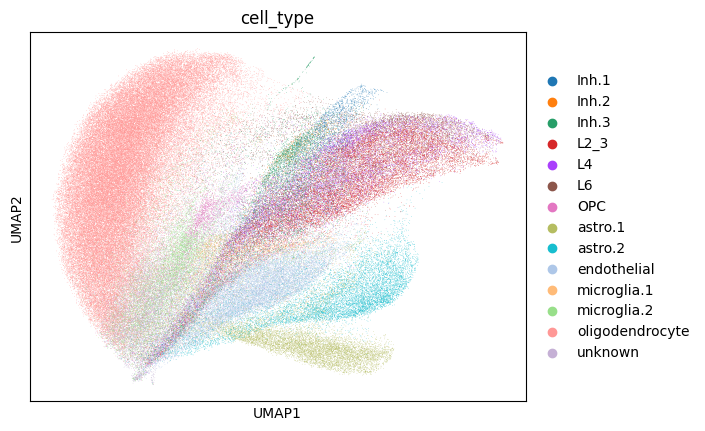

In [12]:
# Visualize cell types in count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

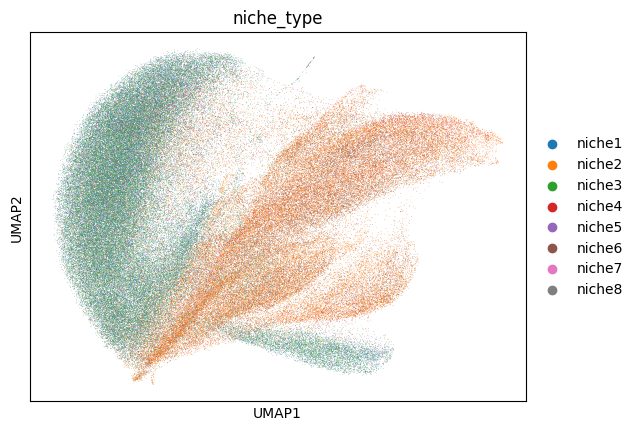

In [13]:
# Visualize niche types in count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])

In [16]:
# Compute UMAP based on (raw) neighborhood counts
sc.pp.pca(adata, layer="X_neighborhood")
sc.pp.neighbors(adata)
sc.tl.umap(adata)

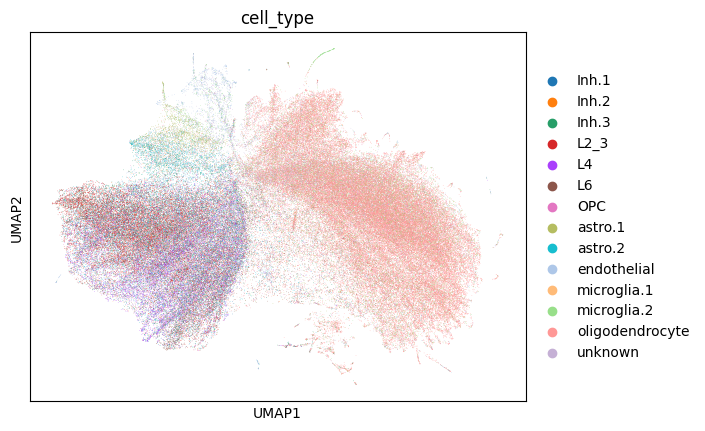

In [17]:
# Visualize cell types in neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

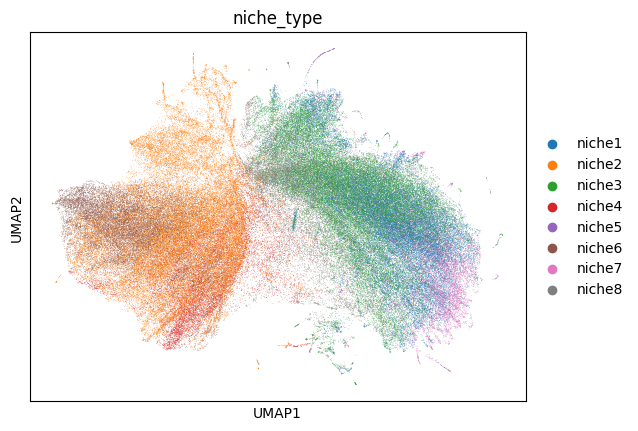

In [18]:
# Visualize niche types in neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])

##### 2.1.2.3 Read Depth Normalized Counts

In [19]:
# Read depth normalize counts
adata.X = adata.X / adata.X.sum(1).reshape(-1, 1) * 10000

In [20]:
# Compute UMAP based on read depth normalized counts
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

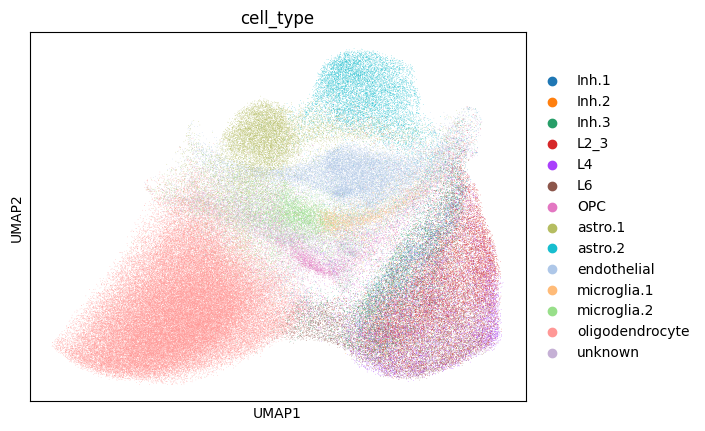

In [21]:
# Visualize cell types in read depth normalized count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

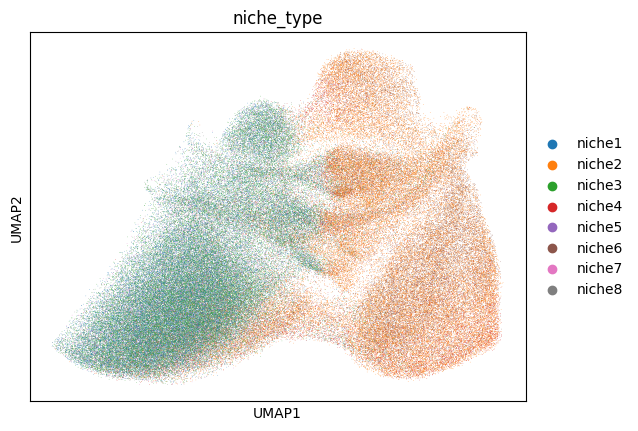

In [22]:
# Visualize niche types in read depth normalized count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])

In [23]:
# Read depth normalize neighborhood counts
adata.layers["X_neighborhood"] = (
    adata.layers["X_neighborhood"] /
    adata.layers["X_neighborhood"].sum(1).reshape(-1, 1) *
    10000)

In [24]:
# Compute UMAP based on read depth normalized neighborhood counts
sc.pp.pca(adata, layer="X_neighborhood")
sc.pp.neighbors(adata)
sc.tl.umap(adata)

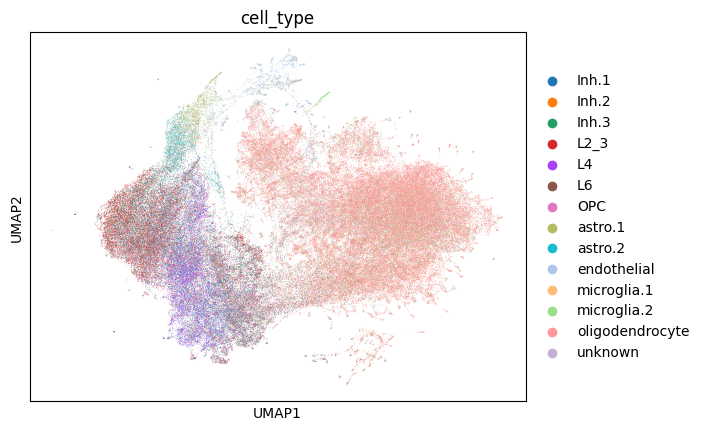

In [25]:
# Visualize cell types in depth normalized neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

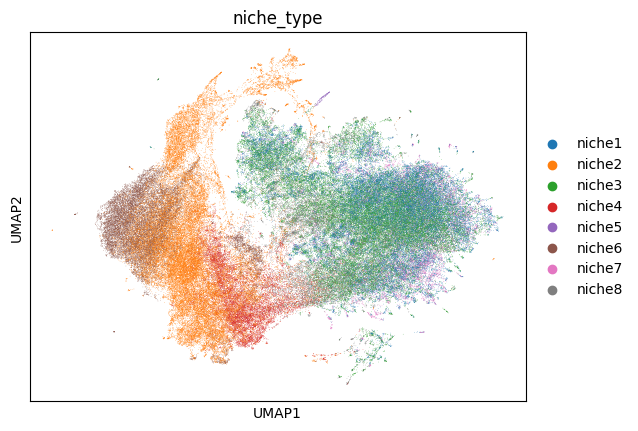

In [26]:
# Visualize niche types in depth normalized neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])

##### 2.1.2.4 Mean Reg Std Normalized Counts (Seurat V3)

In [28]:
# Compute means and vars of read-depth normalized cell gene counts
cell_gene_means = np.mean(adata.X, axis=0)
cell_gene_vars = np.var(adata.X, axis=0)

# Compute means and vars of read-depth normalized neighborhood gene counts
neighborhood_gene_means = np.mean(adata.layers["X_neighborhood"], axis=0)
neighborhood_gene_vars = np.var(adata.layers["X_neighborhood"], axis=0)

# Learn mean-variance relationships for cell and neighborhood genes respectively
# to remove (only) expected variance based on mean to stabilize variances across genes.
# Inspired by seurat scaling to determine highly variable genes
# https://github.com/scverse/scanpy/blob/4642cf8e2e51b257371792cb4fcb9611c0a81123/scanpy/preprocessing/_highly_variable_genes.py#L26
not_const_cell_genes = cell_gene_vars > 0
cell_gene_est_log_vars = np.zeros(adata.shape[1], dtype=np.float64)
y = np.log10(cell_gene_vars[not_const_cell_genes])
x = np.log10(cell_gene_means[not_const_cell_genes])
cell_gene_model = loess(x, y, span=0.3, degree=2)
cell_gene_model.fit()
cell_gene_est_log_vars[not_const_cell_genes] = cell_gene_model.outputs.fitted_values
cell_gene_reg_stds = np.sqrt(10**cell_gene_est_log_vars)

not_const_neighborhood_genes = neighborhood_gene_vars > 0
neighborhood_gene_est_log_vars = np.zeros(adata.shape[1], dtype=np.float64)
y = np.log10(neighborhood_gene_vars[not_const_neighborhood_genes])
x = np.log10(neighborhood_gene_means[not_const_neighborhood_genes])
neighborhood_gene_model = loess(x, y, span=0.3, degree=2)
neighborhood_gene_model.fit()
neighborhood_gene_est_log_vars[not_const_neighborhood_genes] = neighborhood_gene_model.outputs.fitted_values
neighborhood_gene_reg_stds = np.sqrt(10**neighborhood_gene_est_log_vars)

# Normalize cell and neighborhood gene counts by mean and reg std
adata.X = (adata.X - cell_gene_means) / cell_gene_reg_stds
adata.layers["X_neighborhood"] = (
    adata.layers["X_neighborhood"] - neighborhood_gene_means) / neighborhood_gene_reg_stds

In [29]:
# Compute UMAP based on mean std normalized counts
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

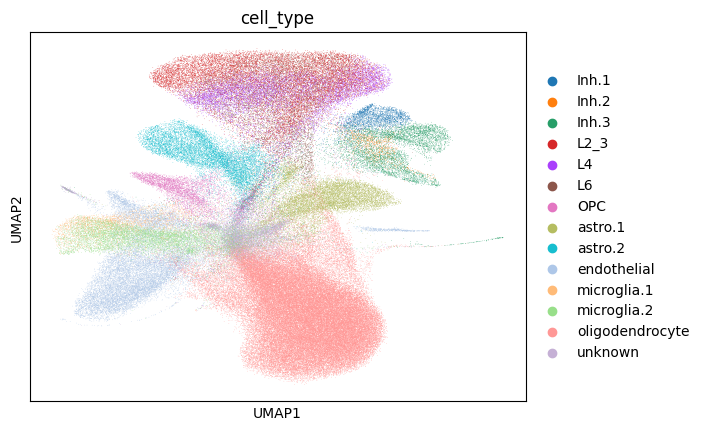

In [30]:
# Visualize cell types in mean std normalized count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

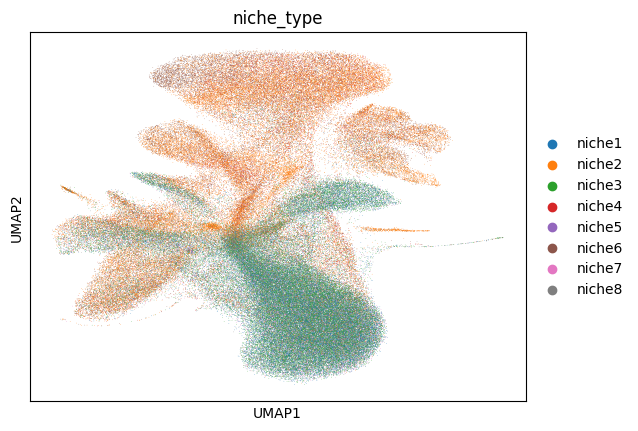

In [31]:
# Visualize niche types in mean std normalized count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])

In [32]:
# Compute UMAP based on mean std normalized neighborhood counts
sc.pp.pca(adata, layer="X_neighborhood")
sc.pp.neighbors(adata)
sc.tl.umap(adata)

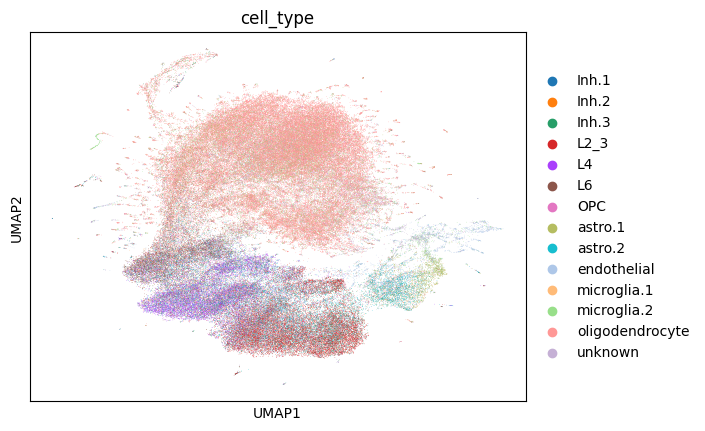

In [33]:
# Visualize cell types in mean std normalized neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

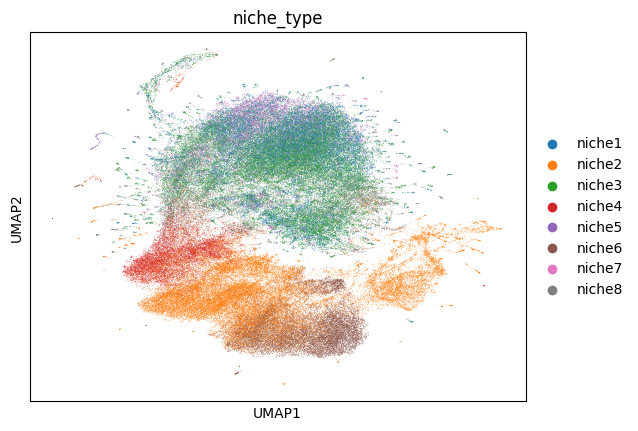

In [34]:
# Visualize niche types in mean std normalized neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])

##### 2.1.2.5 Non-zero Median Division Normalized Counts (Geneformer)

In [35]:
# Reverse mean and reg std normalization
adata.X = adata.X * cell_gene_reg_stds + cell_gene_means
adata.layers["X_neighborhood"] = (
    adata.layers["X_neighborhood"] * neighborhood_gene_reg_stds + neighborhood_gene_means)

# Compute non-zero medians
masked_data = np.ma.masked_equal(adata.X, 0)
cell_gene_nzmedians = np.ma.mean(masked_data, axis=0)
cell_gene_nzmedians = cell_gene_nzmedians.filled(0)
masked_data_neighborhood = np.ma.masked_equal(adata.layers["X_neighborhood"], 0)
neighborhood_gene_nzmedians = np.ma.mean(masked_data_neighborhood, axis=0)
neighborhood_gene_nzmedians = neighborhood_gene_nzmedians.filled(0)

# Perform non-zero median division normalization
adata.X = adata.X / cell_gene_nzmedians
adata.layers["X_neighborhood"] = adata.layers["X_neighborhood"] / neighborhood_gene_nzmedians

In [36]:
# Compute UMAP based on non-zero median division normalized counts
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

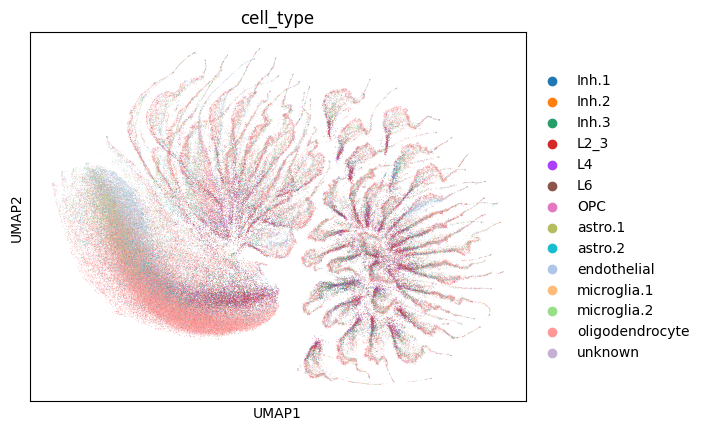

In [37]:
# Visualize cell types in non-zero median division normalized count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

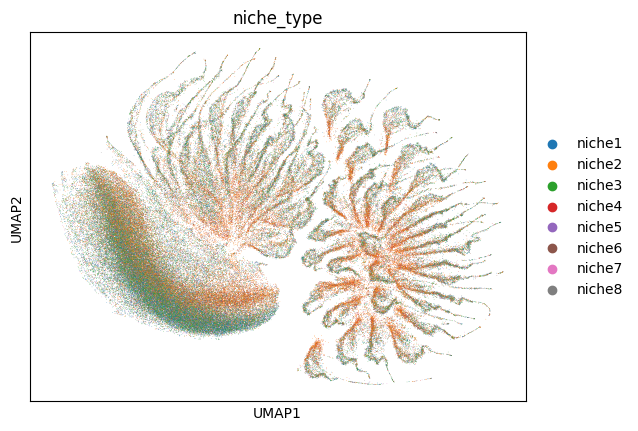

In [38]:
# Visualize niche types in non-zero median division normalized count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])

In [39]:
# Compute UMAP based on non-zero median division normalized neighborhood counts
sc.pp.pca(adata, layer="X_neighborhood")
sc.pp.neighbors(adata)
sc.tl.umap(adata)

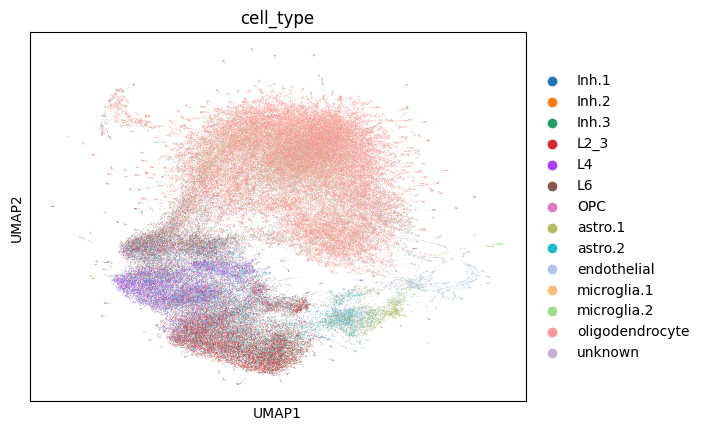

In [40]:
# Visualize cell types in non-zero median division normalized neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["cell_type"])

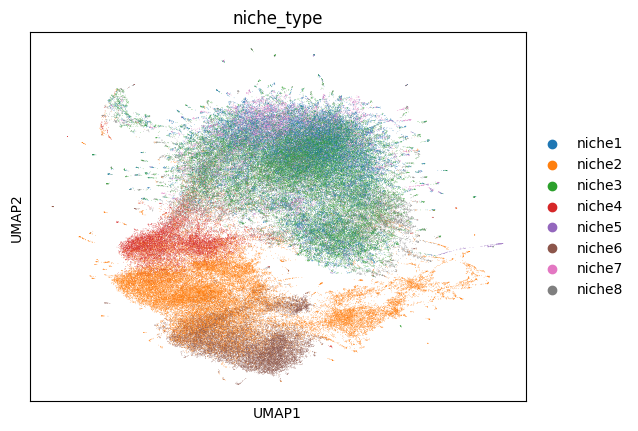

In [41]:
# Visualize niche types in non-zero median division normalized neighborhood-count-based UMAP space
sc.pl.umap(adata,
           color=["niche_type"])